# DS1 clustering

Checks whether DS1 patients form natural groups without using the diagnosis, and whether those groups match CKD vs not CKD. Same four methods as DS2: k-means, hierarchical, Gaussian mixture and DBSCAN. Input is the processed training set from `DS1_Data_Preprocessing.ipynb`. DS1 is real hospital data, so it shows what clustering finds when the features carry real signal.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score

RANDOM_STATE = 42

## 1. Load the processed training set

In [2]:
train = pd.read_csv("../../../../assets/datasets/1_UCI_Chronic_Kidney_Disease_Dataset/processed/train.csv")
X = train.drop(columns=["Target"])
y = train["Target"]
short = ["Not CKD", "CKD"]

X_s, y_s = X, y
print(X.shape)

(320, 24)


**Observation:**
- Target is only used to compare with the clusters, never to fit them
- All 320 training rows are used, as the dataset is small enough for every method

## 2. Look for structure with PCA

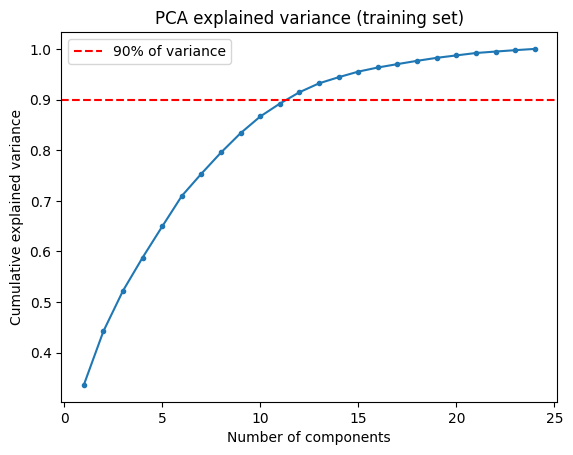

Components for 90%: 12 of 24


In [3]:
pca = PCA(random_state=RANDOM_STATE).fit(X)
cum = np.cumsum(pca.explained_variance_ratio_)

plt.plot(range(1, len(cum) + 1), cum, marker=".")
plt.axhline(0.9, color="red", linestyle="--", label="90% of variance")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA explained variance (training set)")
plt.legend()
plt.show()
print("Components for 90%:", (cum < 0.9).sum() + 1, "of", X.shape[1])

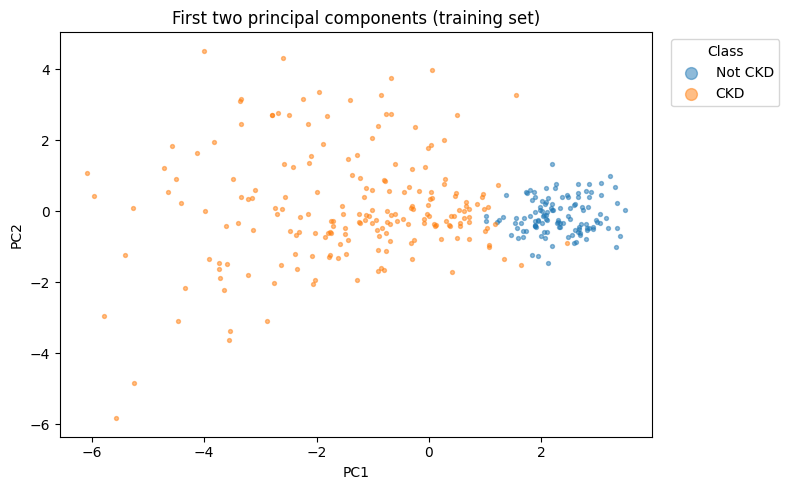

In [4]:
pcs = PCA(n_components=2, random_state=RANDOM_STATE).fit(X).transform(X_s)

fig, ax = plt.subplots(figsize=(8, 5))
for k, s in enumerate(short):
    m = (y_s == k).values
    ax.scatter(pcs[m, 0], pcs[m, 1], s=8, alpha=0.5, label=s)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend(title="Class", markerscale=3, bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_title("First two principal components (training set)")
fig.tight_layout()
plt.show()

**Observation:**
- 12 of 24 components are needed for 90% of the variance
- In the first two components, not-CKD patients form a tight group, while CKD patients are spread widely

## 3. Hierarchical clustering

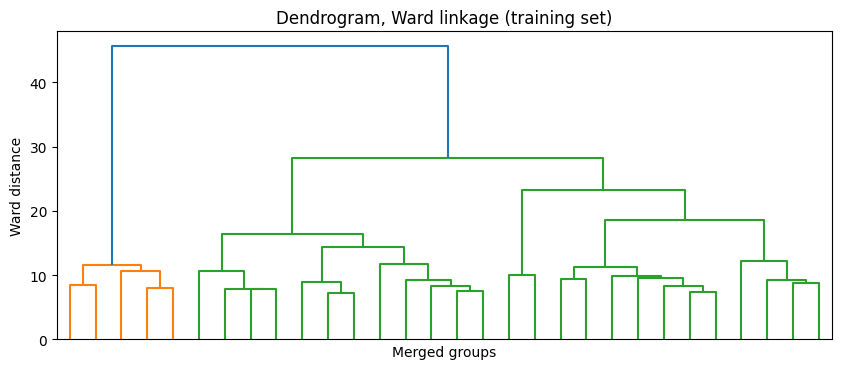

In [5]:
Z = linkage(X_s, method="ward")

plt.figure(figsize=(10, 4))
dendrogram(Z, truncate_mode="lastp", p=30, no_labels=True)
plt.xlabel("Merged groups")
plt.ylabel("Ward distance")
plt.title("Dendrogram, Ward linkage (training set)")
plt.show()

**Observation:**
- One long gap at the top of the dendrogram, so the data splits clearly into 2 groups

## 4. Choose the number of clusters

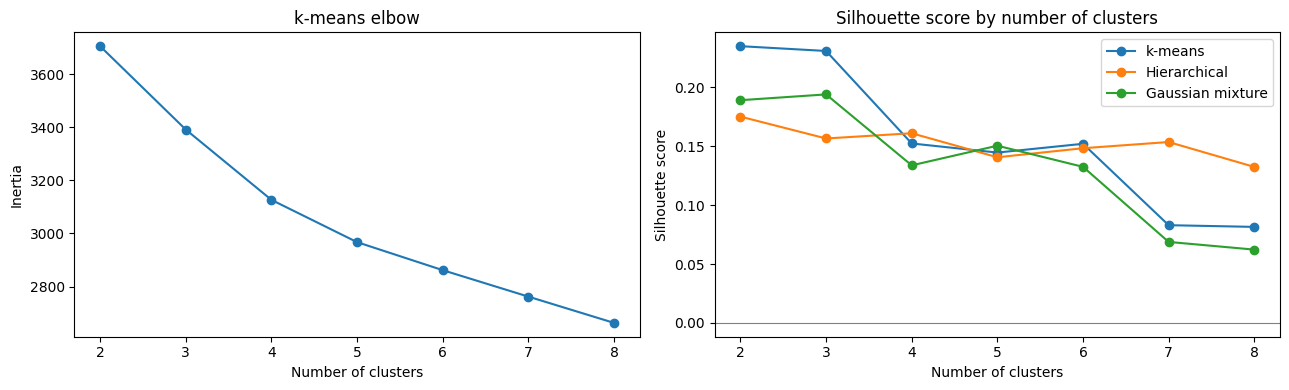

,k-means,Hierarchical,Gaussian mixture
2,0.235,0.175,0.189
3,0.231,0.157,0.194
4,0.152,0.161,0.134
5,0.145,0.141,0.150
6,0.152,0.148,0.133
7,0.083,0.154,0.069
8,0.082,0.132,0.062


In [6]:
ks = range(2, 9)
km_models = {k: KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(X) for k in ks}
gmm_labels = {k: GaussianMixture(k, covariance_type="diag", random_state=RANDOM_STATE).fit(X).predict(X_s) for k in ks}

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(list(ks), [km_models[k].inertia_ for k in ks], marker="o")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Inertia")
axes[0].set_title("k-means elbow")

sil = pd.DataFrame({
    "k-means": [silhouette_score(X_s, km_models[k].predict(X_s)) for k in ks],
    "Hierarchical": [silhouette_score(X_s, AgglomerativeClustering(k, linkage="ward").fit_predict(X_s)) for k in ks],
    "Gaussian mixture": [silhouette_score(X_s, gmm_labels[k]) for k in ks],
}, index=ks)
sil.plot(marker="o", ax=axes[1])
axes[1].axhline(0, color="grey", linewidth=0.8)
axes[1].set_xlabel("Number of clusters")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette score by number of clusters")
fig.tight_layout()
plt.show()
display(sil.round(3) + 0.0)

**Observation:**
- The k-means elbow curve has no sharp bend
- Silhouette is highest at 2 or 3 clusters for every method (up to 0.24), far above DS2 (about 0.02)

## 5. DBSCAN

In [7]:
dist = np.sort(NearestNeighbors(n_neighbors=5).fit(X_s).kneighbors(X_s)[0][:, -1])
rows = []
for p in [10, 25, 50, 75, 90]:
    eps = np.percentile(dist, p)
    labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X_s)
    rows.append({
        "eps percentile": p,
        "eps": round(eps, 2),
        "Clusters": len(set(labels)) - (-1 in labels),
        "Noise %": round((labels == -1).mean() * 100, 1),
        "Adjusted Rand index": round(adjusted_rand_score(y_s, labels), 3) + 0.0,
    })
display(pd.DataFrame(rows).set_index("eps percentile"))
print("Distance to 5th nearest neighbour:", round(dist.min(), 2), "to", round(dist.max(), 2))

,eps,Clusters,Noise %,Adjusted Rand index
eps percentile,,,,
10,1.83,3,78.4,0.392
25,2.05,3,61.9,0.664
50,2.64,1,40.9,0.320
75,3.41,1,16.2,-0.025
90,4.24,1,5.3,-0.031


Distance to 5th nearest neighbour: 1.49 to 6.36


**Observation:**
- Distances to the 5th nearest neighbour vary a lot (1.5 to 6.4), unlike DS2
- At the 25th percentile eps, DBSCAN finds a dense group of healthy patients and marks most CKD patients as noise (Adjusted Rand index 0.66), as CKD patients vary much more

## 6. Compare clusters with the class

,Adjusted Rand index,Silhouette
k-means,0.420,0.235
Hierarchical,0.950,0.175
Gaussian mixture,0.208,0.189


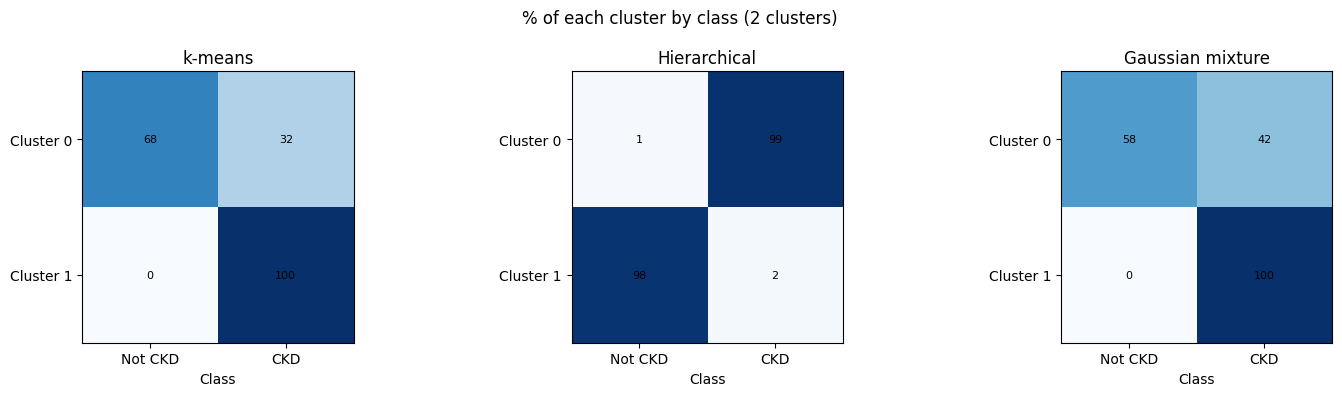

In [8]:
labels = {
    "k-means": km_models[2].predict(X_s),
    "Hierarchical": AgglomerativeClustering(2, linkage="ward").fit_predict(X_s),
    "Gaussian mixture": gmm_labels[2],
}
display(pd.DataFrame({
    "Adjusted Rand index": [adjusted_rand_score(y_s, l) for l in labels.values()],
    "Silhouette": [silhouette_score(X_s, l) for l in labels.values()],
}, index=list(labels)).round(3) + 0.0)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, l) in zip(axes, labels.items()):
    mix = pd.crosstab(l, y_s, normalize="index").mul(100)
    ax.imshow(mix, cmap="Blues", vmin=0, vmax=100)
    ax.set_xticks(range(len(short)), short)
    ax.set_yticks(range(len(mix)), [f"Cluster {i}" for i in mix.index])
    for i in range(mix.shape[0]):
        for j in range(mix.shape[1]):
            ax.text(j, i, f"{mix.iloc[i, j]:.0f}", ha="center", va="center", fontsize=8)
    ax.set_xlabel("Class")
    ax.set_title(name)
fig.suptitle("% of each cluster by class (2 clusters)")
fig.tight_layout()
plt.show()

**Observation:**
- 2 clusters are used to match CKD vs not CKD
- Hierarchical clustering almost exactly recovers the diagnosis (Adjusted Rand index 0.95) without seeing the labels
- k-means and the Gaussian mixture put all healthy patients in one cluster but also pull in many CKD patients (32% and 42% of that cluster), so they split by severity rather than diagnosis
- Silhouette alone would have picked k-means (0.24), which is why the clusters are also checked against the labels
- Unlike DS2, the features clearly separate the classes, so the methods work when the features carry signal

## 7. Clusters vs real labels

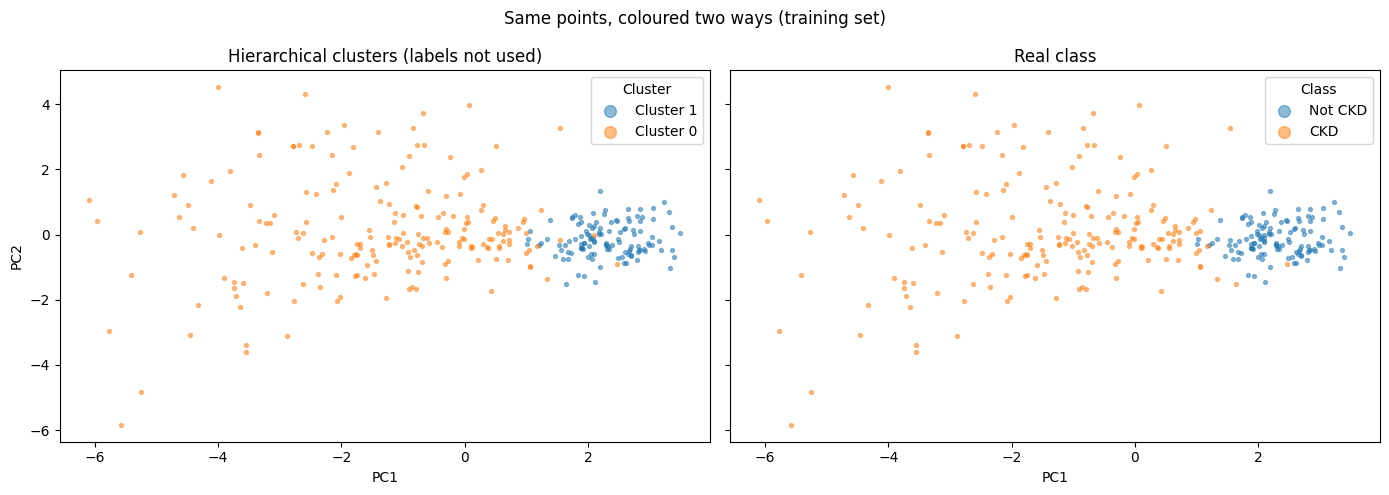

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
for k in pd.crosstab(labels["Hierarchical"], y_s).idxmax(axis=1).sort_values().index:
    m = labels["Hierarchical"] == k
    axes[0].scatter(pcs[m, 0], pcs[m, 1], s=8, alpha=0.5, label=f"Cluster {k}")
for k, s in enumerate(short):
    m = (y_s == k).values
    axes[1].scatter(pcs[m, 0], pcs[m, 1], s=8, alpha=0.5, label=s)
axes[0].set_title("Hierarchical clusters (labels not used)")
axes[1].set_title("Real class")
for ax, t in zip(axes, ["Cluster", "Class"]):
    ax.set_xlabel("PC1")
    ax.legend(title=t, markerscale=3)
axes[0].set_ylabel("PC2")
fig.suptitle("Same points, coloured two ways (training set)")
fig.tight_layout()
plt.show()

**Observation:**
- 

## 8. Check different feature groups

In [10]:
binary = [c for c in X.columns if X[c].nunique() <= 2]
continuous = [c for c in X.columns if X[c].nunique() > 6]
groups = {
    "All features": list(X.columns),
    "Without 0/1 features": [c for c in X.columns if c not in binary],
    "Continuous only": continuous,
    "0/1 features only": binary,
}
display(pd.DataFrame({
    "Features": [len(cols) for cols in groups.values()],
    "Adjusted Rand index": [
        round(adjusted_rand_score(y_s, AgglomerativeClustering(2, linkage="ward").fit_predict(X_s[cols])), 3) + 0.0
        for cols in groups.values()
    ],
}, index=list(groups)))

,Features,Adjusted Rand index
All features,24,0.950
Without 0/1 features,14,0.902
Continuous only,11,0.214
0/1 features only,10,0.743


**Observation:**
- 

## 9. Summary and limitations

- 